In [ ]:
# Cell 1: Setup (one Drive mount, data loaded from Drive, paths for both parts)
import tensorflow as tf
print("GPU:", tf.config.list_physical_devices('GPU'))

import sys, os, json, hashlib, shutil, zipfile
from pathlib import Path
import numpy as np
import pandas as pd
from google.colab import drive

drive.mount('/content/drive')

# --- Dataset on Drive ---
# Your Drive folder is a Hugging Face dataset saved with save_to_disk (dataset_dict.json + arrow files).
# It is exported ONCE per session to a local folder chest_xray_clean/{train,val,test}/{NORMAL,PNEUMONIA}.
DRIVE_DATA = Path('/content/drive/MyDrive/Chest_XRay_Dataset')      # <-- dataset folder on Drive

# --- Data engineering paths ---
DATASET_PATH = Path('/content/chest_xray_clean')                    # local export (fast)
OUTPUT_DIR = Path('/content/drive/MyDrive/Chest_XRay_Week10')
SPLITS = ['train', 'val', 'test']
CLASSES = ['NORMAL', 'PNEUMONIA']


def export_hf_dataset(src, dst):
    """Write a save_to_disk DatasetDict as split/label/image files (raw bytes, no re-encoding)."""
    from datasets import load_from_disk, Image as HFImage
    from tqdm.auto import tqdm
    dd = load_from_disk(str(src))
    split_map = {'train': 'train', 'validation': 'val', 'val': 'val', 'test': 'test'}
    n_named = n_total = 0
    for hf_split, name in split_map.items():
        if hf_split not in dd:
            continue
        part = dd[hf_split].cast_column('image', HFImage(decode=False))
        names = [n.upper() for n in part.features['label'].names]
        assert set(names) == set(CLASSES), f'Unexpected labels: {names}'
        for lbl in CLASSES:
            (dst / name / lbl).mkdir(parents=True, exist_ok=True)
        used = set()
        for i, ex in enumerate(tqdm(part, desc=hf_split)):
            lbl = names[ex['label']]
            orig = Path(ex['image']['path']).name if ex['image'].get('path') else ''
            fname = orig if orig else f'{hf_split}_{i:05d}.jpeg'
            n_named += bool(orig)
            n_total += 1
            if (name, lbl, fname) in used:                      # avoid overwriting duplicates
                fname = f'{hf_split}_{i:05d}_{fname}'
            used.add((name, lbl, fname))
            if not Path(fname).suffix:
                fname += '.jpeg'
            (dst / name / lbl / fname).write_bytes(ex['image']['bytes'])
    print(f'Exported {n_total} images; {n_named} kept their original file name')


if not (DATASET_PATH / 'train' / 'NORMAL').exists():
    if (DRIVE_DATA / 'dataset_dict.json').exists():
        print('Exporting Hugging Face dataset from Drive (one time per session)...')
        export_hf_dataset(DRIVE_DATA, DATASET_PATH)
    else:
        raise FileNotFoundError(f'{DRIVE_DATA} is not a save_to_disk dataset (no dataset_dict.json)')
print('Dataset ready at:', DATASET_PATH, '->', sorted(p.name for p in DATASET_PATH.iterdir()))

# --- Experiments settings ---
AUTHOR = 'YOUR_NAME'                                              # <-- put your name (goes in the log)
EXP_DIR = Path('/content/drive/MyDrive/Chest_XRay_Experiments_v2')   # NEW folder: the old log belongs to the old random split
(EXP_DIR / 'curves').mkdir(parents=True, exist_ok=True)
os.makedirs('src', exist_ok=True)
sys.path.append('src')

GPU: []
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset ready at: /content/chest_xray_clean -> ['test', 'train', 'val']


In [ ]:
# Cell 2: Load image records
records = []
for split in SPLITS:
    for label in CLASSES:
        folder = DATASET_PATH / split / label
        if not folder.exists():
            raise FileNotFoundError(f'Missing folder: {folder}')
        for path in sorted(folder.glob('*')):
            if path.suffix.lower() in ['.jpg', '.jpeg', '.png']:
                records.append({'filepath': str(path), 'filename': path.name,
                                'split': split, 'label': label})

df = pd.DataFrame(records)
print('Total images:', len(df))
display(pd.crosstab(df['split'], df['label']))

Total images: 5856


label,NORMAL,PNEUMONIA
split,,
test,234,390
train,1341,3875
val,8,8


In [ ]:
# Cell 3: Validate images and remove exact duplicates
import hashlib
from PIL import Image
from tqdm.auto import tqdm

valid = []
bad_images = []
for row in tqdm(df.to_dict('records')):
    try:
        with Image.open(row['filepath']) as img:
            img.verify()
        with Image.open(row['filepath']) as img:
            img.load()
        row['hash'] = hashlib.sha256(Path(row['filepath']).read_bytes()).hexdigest()
        valid.append(row)
    except Exception as e:
        bad_images.append(row['filepath'])
        print('Bad image:', row['filepath'], e)

clean_df = pd.DataFrame(valid)
assert clean_df.groupby('hash')['label'].nunique().max() == 1, 'Same image with two labels'

# Keep the Test copy first when an image is duplicated
clean_df['priority'] = (clean_df['split'] != 'test').astype(int)
clean_df = clean_df.sort_values(['priority', 'filepath'])
removed = clean_df[clean_df.duplicated('hash')]
clean_df = clean_df.drop_duplicates('hash').drop(columns='priority').reset_index(drop=True)

print('Bad images:', len(bad_images))
print('Duplicates removed:', len(removed))
print(removed['split'].value_counts())
print('Valid unique images:', len(clean_df))

  0%|          | 0/5856 [00:00<?, ?it/s]

Bad images: 0
Duplicates removed: 32
split
train    26
test      6
Name: count, dtype: int64
Valid unique images: 5824


In [ ]:
# Cell 4: Patient-grouped, stratified train/validation split
from sklearn.model_selection import StratifiedGroupKFold

pattern = r'(person\d+|(?:NORMAL2-)?IM-\d+)'
clean_df['patient_id'] = (clean_df['filename'].str.extract(pattern, expand=False)
                          .fillna(clean_df['filename']))

test_df = clean_df[clean_df['split'] == 'test'].reset_index(drop=True)
dev_df = clean_df[clean_df['split'] != 'test'].reset_index(drop=True)

sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
train_idx, val_idx = next(sgkf.split(dev_df, dev_df['label'], groups=dev_df['patient_id']))
train_df = dev_df.iloc[train_idx].reset_index(drop=True)
val_df = dev_df.iloc[val_idx].reset_index(drop=True)
splits = {'train': train_df, 'validation': val_df, 'test': test_df}

# Leakage checks
for a, b in [(train_df, val_df), (train_df, test_df), (val_df, test_df)]:
    assert set(a['hash']).isdisjoint(b['hash'])
assert set(train_df['patient_id']).isdisjoint(val_df['patient_id'])
print('Hash and train/validation patient checks: PASSED')

counts = pd.DataFrame({k: v['label'].value_counts() for k, v in splits.items()})
display(counts)
display((counts / counts.sum() * 100).round(2))

# IDs that also appear in Test need manual review
shared = set(dev_df['patient_id']) & set(test_df['patient_id'])
print('Patient IDs shared with test:', len(shared))
for pid in sorted(shared)[:5]:
    display(clean_df.loc[clean_df['patient_id'] == pid,
                         ['patient_id', 'split', 'label', 'filename']])

Hash and train/validation patient checks: PASSED


,train,validation,test
label,,,
PNEUMONIA,3094,764,387
NORMAL,1077,271,231


,train,validation,test
label,,,
PNEUMONIA,74.18,73.82,62.62
NORMAL,25.82,26.18,37.38


Patient IDs shared with test: 170


,patient_id,split,label,filename
481,person1,test,PNEUMONIA,person1_virus_11.jpeg
482,person1,test,PNEUMONIA,person1_virus_12.jpeg
483,person1,test,PNEUMONIA,person1_virus_13.jpeg
484,person1,test,PNEUMONIA,person1_virus_6.jpeg
485,person1,test,PNEUMONIA,person1_virus_7.jpeg
486,person1,test,PNEUMONIA,person1_virus_8.jpeg
487,person1,test,PNEUMONIA,person1_virus_9.jpeg
3568,person1,train,PNEUMONIA,person1_bacteria_1.jpeg
3569,person1,train,PNEUMONIA,person1_bacteria_2.jpeg


,patient_id,split,label,filename
261,person10,test,PNEUMONIA,person10_virus_35.jpeg
2136,person10,train,PNEUMONIA,person10_bacteria_43.jpeg


,patient_id,split,label,filename
231,person100,test,PNEUMONIA,person100_bacteria_475.jpeg
232,person100,test,PNEUMONIA,person100_bacteria_477.jpeg
233,person100,test,PNEUMONIA,person100_bacteria_478.jpeg
234,person100,test,PNEUMONIA,person100_bacteria_479.jpeg
235,person100,test,PNEUMONIA,person100_bacteria_480.jpeg
236,person100,test,PNEUMONIA,person100_bacteria_481.jpeg
237,person100,test,PNEUMONIA,person100_bacteria_482.jpeg
1974,person100,train,PNEUMONIA,person100_virus_184.jpeg


,patient_id,split,label,filename
238,person101,test,PNEUMONIA,person101_bacteria_483.jpeg
239,person101,test,PNEUMONIA,person101_bacteria_484.jpeg
240,person101,test,PNEUMONIA,person101_bacteria_485.jpeg
241,person101,test,PNEUMONIA,person101_bacteria_486.jpeg
1990,person101,train,PNEUMONIA,person101_virus_187.jpeg
1991,person101,train,PNEUMONIA,person101_virus_188.jpeg


,patient_id,split,label,filename
242,person102,test,PNEUMONIA,person102_bacteria_487.jpeg
2007,person102,train,PNEUMONIA,person102_virus_189.jpeg


In [ ]:
# Cell 5: Label encoding and class weights (training set only)
import numpy as np
from sklearn.utils.class_weight import compute_class_weight

label_mapping = {'NORMAL': 0, 'PNEUMONIA': 1}
for part in splits.values():
    part['encoded_label'] = part['label'].map(label_mapping)

y_labels = train_df['encoded_label'].to_numpy()
classes = np.unique(y_labels)
weights = compute_class_weight(class_weight='balanced', classes=classes, y=y_labels)
class_weights = {int(c): float(w) for c, w in zip(classes, weights)}

print(train_df['label'].value_counts())
print('Class weights:', class_weights)

# Name used by the experiments part
CLASS_WEIGHTS = class_weights

label
PNEUMONIA    3094
NORMAL       1077
Name: count, dtype: int64
Class weights: {0: 1.936397400185701, 1: 0.6740465416936006}


In [ ]:
# Cell 6: Preprocessing function
IMAGE_SIZE = (224, 224)

def preprocess_image(path):
    """Grayscale, resize, scale to [0, 1] and add a channel axis."""
    with Image.open(path) as img:
        img = img.convert('L').resize(IMAGE_SIZE, Image.Resampling.LANCZOS)
        array = np.asarray(img, dtype=np.float32) / 255.0
    return array[..., np.newaxis]

sample = preprocess_image(train_df.iloc[0]['filepath'])
print(sample.shape, sample.dtype, sample.min(), sample.max())

(224, 224, 1) float32 0.0 0.98039216


In [ ]:
# Cell 7: Process all splits
def process_split(part):
    """Return images and labels of one split."""
    X = np.stack([preprocess_image(p) for p in tqdm(part['filepath'])])
    y = part['encoded_label'].to_numpy(dtype=np.int64)
    return X, y

X_train, y_train = process_split(train_df)
X_val, y_val = process_split(val_df)
X_test, y_test = process_split(test_df)

arrays = {'train': (X_train, y_train), 'validation': (X_val, y_val),
          'test': (X_test, y_test)}

for name, (X, y) in arrays.items():
    print(name, X.shape, y.shape)
    assert X.shape == (len(splits[name]), 224, 224, 1)
    assert np.array_equal(y, splits[name]['encoded_label'].to_numpy())
    assert X.min() >= 0 and X.max() <= 1
print('Processing checks: PASSED')

  0%|          | 0/4171 [00:00<?, ?it/s]

  0%|          | 0/1035 [00:00<?, ?it/s]

  0%|          | 0/618 [00:00<?, ?it/s]

train (4171, 224, 224, 1) (4171,)
validation (1035, 224, 224, 1) (1035,)
test (618, 224, 224, 1) (618,)
Processing checks: PASSED


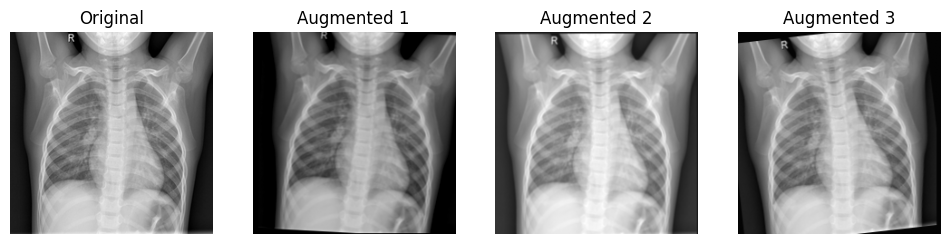

In [ ]:
# Cell 8: Augmentation (training only) with preview
import tensorflow as tf
import matplotlib.pyplot as plt

augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(7 / 360, fill_mode='constant', seed=42),
    tf.keras.layers.RandomTranslation(0.03, 0.03, fill_mode='constant', seed=43),
    tf.keras.layers.RandomBrightness(0.10, value_range=(0.0, 1.0), seed=44),
])

plt.figure(figsize=(12, 3))
for i in range(4):
    image = X_train[:1] if i == 0 else augmentation(X_train[:1], training=True).numpy()
    plt.subplot(1, 4, i + 1)
    plt.imshow(image[0, ..., 0], cmap='gray', vmin=0, vmax=1)
    plt.title('Original' if i == 0 else f'Augmented {i}')
    plt.axis('off')
plt.show()

In [ ]:
# Cell 9: tf.data pipelines and saving
import json
BATCH_SIZE = 32

def make_dataset(X, y, training=False):
    """Build a dataset. Augmentation is applied to training batches only."""
    ds = tf.data.Dataset.from_tensor_slices((X, y))
    if training:
        ds = ds.shuffle(len(X), seed=42)
    ds = ds.batch(BATCH_SIZE)
    if training:
        ds = ds.map(lambda a, b: (augmentation(a, training=True), b))
    return ds.prefetch(tf.data.AUTOTUNE)

train_ds = make_dataset(X_train, y_train, training=True)
val_ds = make_dataset(X_val, y_val)
test_ds = make_dataset(X_test, y_test)

images, labels = next(iter(train_ds))
print('Train batch:', images.shape, float(tf.reduce_min(images)), float(tf.reduce_max(images)))

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
for name, (X, y) in arrays.items():
    np.savez_compressed(OUTPUT_DIR / f'{name}_data.npz', X=X, y=y)

manifest = pd.concat([
    part.assign(original_split=part['split'], split=name,
                filepath=[Path(p).relative_to(DATASET_PATH).as_posix()
                          for p in part['filepath']])
    for name, part in splits.items()
])
manifest.to_csv(OUTPUT_DIR / 'splits.csv', index=False)

config = {'label_mapping': label_mapping, 'class_weights': class_weights,
          'image_size': list(IMAGE_SIZE), 'color_mode': 'grayscale',
          'resize': 'LANCZOS', 'scale': 'divide by 255', 'seed': 42}
(OUTPUT_DIR / 'preprocessing_config.json').write_text(json.dumps(config, indent=2))
print('Saved:', sorted(p.name for p in OUTPUT_DIR.iterdir()))

Train batch: (32, 224, 224, 1) 0.0 1.0
Saved: ['data.py', 'preprocessing_config.json', 'splits.csv', 'test_data.npz', 'train_data.npz', 'validation_data.npz']


In [ ]:
%%writefile src/data.py
"""Data loading, cleaning, splitting and preprocessing for Chest X-Ray."""
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import tensorflow as tf
from PIL import Image
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.utils.class_weight import compute_class_weight

LABEL_MAPPING = {'NORMAL': 0, 'PNEUMONIA': 1}
IMAGE_SIZE = (224, 224)
SEED = 42


def load_records(dataset_path):
    """List all images under split/label folders."""
    records = []
    for split in ['train', 'val', 'test']:
        for label in LABEL_MAPPING:
            folder = Path(dataset_path) / split / label
            if not folder.exists():
                raise FileNotFoundError(f'Missing folder: {folder}')
            for path in sorted(folder.glob('*')):
                if path.suffix.lower() in ['.jpg', '.jpeg', '.png']:
                    records.append({'filepath': str(path), 'filename': path.name,
                                    'split': split, 'label': label})
    return pd.DataFrame(records)


def clean_data(df):
    """Drop unreadable images and exact duplicates, keeping test copies."""
    valid = []
    for row in df.to_dict('records'):
        try:
            with Image.open(row['filepath']) as img:
                img.verify()
            with Image.open(row['filepath']) as img:
                img.load()
            row['hash'] = hashlib.sha256(Path(row['filepath']).read_bytes()).hexdigest()
            valid.append(row)
        except Exception as error:
            print('Bad image:', row['filepath'], error)
    clean = pd.DataFrame(valid)
    if clean.groupby('hash')['label'].nunique().max() > 1:
        raise ValueError('Same image with two labels')
    clean['priority'] = (clean['split'] != 'test').astype(int)
    clean = clean.sort_values(['priority', 'filepath']).drop_duplicates('hash')
    return clean.drop(columns='priority').reset_index(drop=True)


def split_data(df):
    """Keep test; split train+val about 80/20, grouped by patient ID."""
    pattern = r'(person\d+|(?:NORMAL2-)?IM-\d+)'
    ids = df['filename'].str.extract(pattern, expand=False).fillna(df['filename'])
    df = df.assign(patient_id=ids, encoded_label=df['label'].map(LABEL_MAPPING))
    test = df[df['split'] == 'test'].reset_index(drop=True)
    dev = df[df['split'] != 'test'].reset_index(drop=True)
    splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
    train_idx, val_idx = next(splitter.split(dev, dev['label'], dev['patient_id']))
    train = dev.iloc[train_idx].reset_index(drop=True)
    val = dev.iloc[val_idx].reset_index(drop=True)
    for a, b in [(train, val), (train, test), (val, test)]:
        assert set(a['hash']).isdisjoint(b['hash']), 'Duplicate across splits'
    assert set(train['patient_id']).isdisjoint(val['patient_id']), 'Patient leak'
    return {'train': train, 'validation': val, 'test': test}


def get_class_weights(train):
    """Compute balanced class weights from training data only."""
    y = train['encoded_label'].to_numpy()
    classes = np.unique(y)
    weights = compute_class_weight(class_weight='balanced', classes=classes, y=y)
    return {int(c): float(w) for c, w in zip(classes, weights)}


def preprocess_image(path):
    """Grayscale, resize, scale to [0, 1] and add a channel axis."""
    with Image.open(path) as img:
        img = img.convert('L').resize(IMAGE_SIZE, Image.Resampling.LANCZOS)
        array = np.asarray(img, dtype=np.float32) / 255.0
    return array[..., np.newaxis]


def process_split(part):
    """Return images and labels of one split."""
    X = np.stack([preprocess_image(p) for p in part['filepath']])
    return X, part['encoded_label'].to_numpy(dtype=np.int64)


def build_augmentation():
    """Mild augmentations for training images."""
    return tf.keras.Sequential([
        tf.keras.layers.RandomRotation(7 / 360, fill_mode='constant', seed=SEED),
        tf.keras.layers.RandomTranslation(0.03, 0.03, fill_mode='constant',
                                          seed=SEED + 1),
        tf.keras.layers.RandomBrightness(0.10, value_range=(0.0, 1.0),
                                         seed=SEED + 2),
    ])


def make_dataset(X, y, training=False, augment=True, batch_size=32):
    """Build a dataset. Set augment=False for the no-augmentation ablation."""
    ds = tf.data.Dataset.from_tensor_slices((X, y))
    if training:
        ds = ds.shuffle(len(X), seed=SEED)
    ds = ds.batch(batch_size)
    if training and augment:
        augmentation = build_augmentation()
        ds = ds.map(lambda a, b: (augmentation(a, training=True), b))
    return ds.prefetch(tf.data.AUTOTUNE)

Overwriting src/data.py


In [ ]:
# Cell 10: Check that data.py gives the same split, then copy it to Drive
import sys, shutil
sys.path.append('src')
import data

check = data.split_data(data.clean_data(data.load_records(DATASET_PATH)))
for name in splits:
    assert set(check[name]['filepath']) == set(splits[name]['filepath']), name
data.make_dataset(X_train[:32], y_train[:32], training=True).take(1).get_single_element()

shutil.copy('src/data.py', OUTPUT_DIR / 'data.py')
print('data.py check: PASSED')

data.py check: PASSED
